# COU 07506 Digital Signal Processing — Week 01: Lab 0

Name: Phocus A Massawe

Registration No.: 240242412047

Class: BEng24 COE | Group: 01 | Date: 25/11/2026

Instructor checkpoints signed: [ ] 1

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

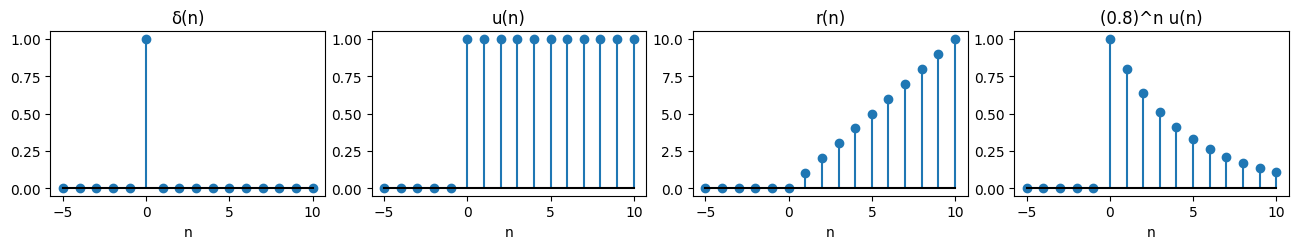

In [9]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)   # unit impulse
step  = (n >= 0).astype(float)   # unit step
ramp  = n * step                 # unit ramp
expo  = 0.8**n * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

 (Task 1.2, part 1):a = 1.1 grows without stopping, because each step multiplies the value by a number bigger than 1.

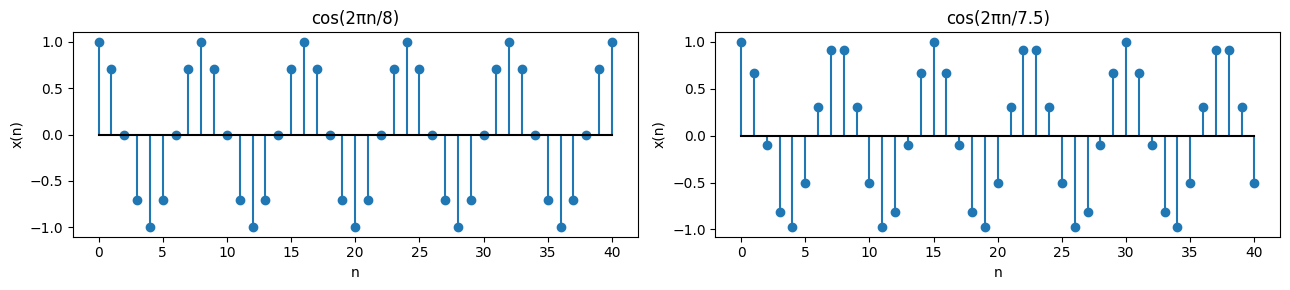

In [10]:
n = np.arange(0, 41)

fig, axes = plt.subplots(1, 2, figsize=(13, 3))
for ax, period in zip(axes, [8, 7.5]):
    x = np.cos(2*np.pi*n/period)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"cos(2πn/{period})")
    ax.set_xlabel("n")
    ax.set_ylabel("x(n)")
plt.tight_layout(); plt.show()


(Task 1.2, part 2):cos(2πn/8) repeats exactly. Its period is 8 samples, a whole number, so the same pattern of values repeats every 8 samples. cos(2πn/7.5) does not repeat every 7.5 samples because samples only exist at whole numbers of n. Its pattern only repeats after 15 samples (two cycles).

fs = 44100 Hz, duration = 5.04 s, samples = 222208


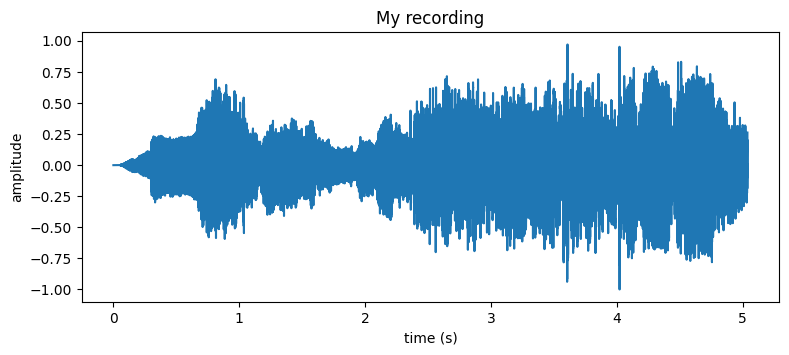

In [11]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))

else:

    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [12]:
from IPython.display import Audio
Audio(x, rate=fs)

PRE LAB


## Pre-lab

Three devices I used today that contain DSP:

1. **Laptop:** it processes the audio signal going to the speakers or headphones, converting digital numbers back into sound.
2. **Phone:** it processes my voice signal from the microphone, which is converted to numbers, cleaned of noise and compressed.
3. **Wi-Fi router or mobile network:** it processes the radio signal carrying data, which is filtered and decoded into bits.

ANALYSIS QUESTIONS

1. The sampling rate for the phone recording is 44100 Hz  and numbers needed to store one minute of it in mono is 2,646,000.
2. A steam plot because x(n) only exists at whole-number positions, with nothing in between. A smooth line would pretend there are values between the dots.
3. A property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7a) is that the signal never dies out, so the system would be unstable (a small input gives an output that grows forever).


AI-use statement

AI tools used: Claude
Used for: step-by-step guidance on running Tasks 1.1–1.3 in Colab

How I verified the output: compared my plots with the expected figures in the lab manual and checked the printed sampling rate and duration of my recording
I confirm that I understand and can explain all submitted code.